# Domain models: phase steps, tilts or bending?

A split or streaked Bragg peak can come from domains whose lattice planes
are offset (phase steps), from slightly tilted domains, or from one
smoothly bent crystal. Phase retrieval from random starts may return any
of these pictures, often as parallel bands separated by low-amplitude
planes. This notebook shows how `cdiutils.simulation.domains` tests the
pictures against the **measured intensity** instead of reading the
reconstruction.

Everything here is synthetic, so the right answer is known:

1. a rod made of three domains with phase steps;
2. a continuous rod with a quadratic phase (bent).

Each dataset is fitted with every model. The method is trustworthy only if
it picks the true model in both cases.

Conventions (as for measured data): arrays are in the detector frame of
the phasing, the intensity is `|fftshift(fftn(ifftshift(obj)))|**2`
(PyNX convention), phases are written on coordinates centred on `n // 2`.
See the user guide page *Domain Models: Phase Steps, Tilts or Bending*.

In [1]:
# imports
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import fftn, fftshift, ifftn, ifftshift

from cdiutils.simulation import (
    DomainModelFit,
    fit_quadratic_phase,
    measure_domain_phases,
    segment_domains,
)

In [2]:
# helpers: Poisson intensity in the PyNX convention, and a band-limited
# copy of an object that mimics the finite resolution of a reconstruction


def simulate_intensity(obj, photons, seed=0):
    '''
    Poisson intensity of an object in the PyNX convention.

    Args:
        obj: Complex object.
        photons: Expected total number of photons.
        seed: Random seed.

    Returns:
        Intensity array (photons).
    '''
    field = fftshift(fftn(ifftshift(obj)))
    intensity = np.abs(field) ** 2
    intensity *= photons / intensity.sum()
    return np.random.default_rng(seed).poisson(intensity).astype(float)


def band_limited(obj, fraction):
    '''
    Keep only the central part of reciprocal space (finite resolution).

    Args:
        obj: Complex object.
        fraction: Fraction of each axis kept around the centre.

    Returns:
        Band-limited complex object.
    '''
    field = fftshift(fftn(ifftshift(obj)))
    keep = np.zeros(obj.shape, dtype=bool)
    keep[tuple(slice(int(n * (1 - fraction) / 2),
                     int(n * (1 + fraction) / 2)) for n in obj.shape)] = True
    return fftshift(ifftn(ifftshift(field * keep)))

## 1. Known answer A: three domains with phase steps

A rod of 12 x 12 x 33 voxels split into three slabs along the last axis,
with constant phases 0, 0.9π and -0.4 rad.

In [3]:
# the true object: one rod, three slabs, constant phase steps
shape = (48, 48, 48)
slabs = np.zeros(shape, dtype=np.int32)
slabs[18:30, 18:30, 8:19] = 1
slabs[18:30, 18:30, 19:30] = 2
slabs[18:30, 18:30, 30:41] = 3
steps_true = np.array([0.0, 0.9 * np.pi, -0.4])
obj_steps = np.zeros(shape, dtype=complex)
for label, phase in enumerate(steps_true, start=1):
    obj_steps[slabs == label] = np.exp(1j * phase)

# measured intensity: 2e7 photons, no masked voxel here
iobs_steps = simulate_intensity(obj_steps, 2e7)
mask = np.zeros(shape, dtype=np.int8)

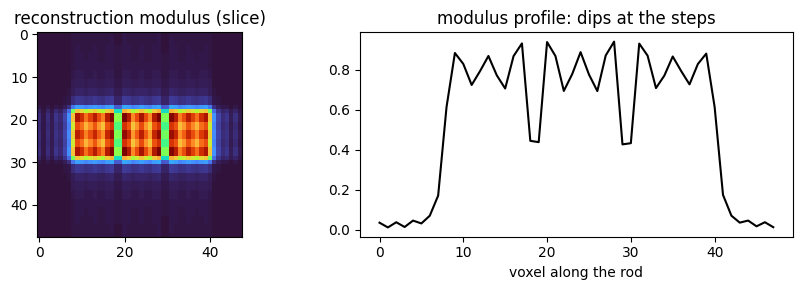

In [4]:
# a band-limited "reconstruction": the modulus drops at each phase step
recon_steps = band_limited(obj_steps, 0.5)
modulus = np.abs(recon_steps) / np.abs(recon_steps).max()

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(modulus[24], cmap="turbo")
axes[0].set_title("reconstruction modulus (slice)")
axes[1].plot(modulus[24, 24], "k")
axes[1].set_xlabel("voxel along the rod")
axes[1].set_title("modulus profile: dips at the steps")
fig.tight_layout()

In [5]:
# segment the domains and measure their phases
domains, seeds = segment_domains(np.abs(recon_steps), seed_threshold=0.5,
                                 outline_threshold=0.2)
phases = measure_domain_phases(recon_steps, seeds)
for domain in phases:
    print(f"domain {domain['label']}: {domain['size']} voxels, "
          f"offset {domain['offset']:+.2f} rad, "
          f"coherence {domain['coherence']:.3f}")
ramps = np.array([domain["ramp"] for domain in phases])

domain 1: 1288 voxels, offset -0.41 rad, coherence 1.000
domain 2: 1288 voxels, offset -0.00 rad, coherence 1.000
domain 3: 1180 voxels, offset +2.83 rad, coherence 1.000


## 2. Known answer B: one bent rod

The same outline, continuous, with a quadratic phase along the rod
(h = 0.03 rad/voxel², i.e. about 8 rad between the centre and the ends).

In [6]:
# the true object: continuous rod with a quadratic phase along axis 2
outline = slabs > 0
x = np.arange(shape[2]) - shape[2] // 2
curvature_true = 0.03
obj_bent = outline * np.exp(1j * curvature_true * x[None, None, :] ** 2)
iobs_bent = simulate_intensity(obj_bent, 2e7, seed=1)

# a band-limited reconstruction of it, and the quadratic phase it carries
recon_bent = band_limited(obj_bent, 0.5)
ramp_start, quadratic_start = fit_quadratic_phase(recon_bent, outline)
print("starting h_22:", round(quadratic_start[2], 4),
      "rad/voxel^2 (true", curvature_true, ")")

starting h_22: 0.0291 rad/voxel^2 (true 0.03 )


## 3. Fit every model to both datasets

* `C`: one common ramp, no steps; `A`: phase steps; `B`: tilted domains,
  all on the three slabs;
* `bend`: one continuous rod with a linear + quadratic phase.

The deviance compares models on the same data; lower is better.

In [7]:
# fit the domain models (three slabs) and the bend model (one outline)
results = {}
for name, iobs in (("steps data", iobs_steps), ("bent data", iobs_bent)):
    slab_fitter = DomainModelFit(iobs, mask, slabs)
    rod_fitter = DomainModelFit(iobs, mask, outline.astype(np.int32))
    results[name] = {
        "C": slab_fitter.fit("C", ramps=ramps),
        "A": slab_fitter.fit("A", ramps=ramps, n_starts=4),
        "B": slab_fitter.fit("B", ramps=ramps, maxiter=40),
        "bend": rod_fitter.fit("bend", ramps=ramp_start[None],
                               quadratics=quadratic_start[None],
                               maxiter=40),
    }

In [8]:
# deviance table (1e6) and number of parameters
print(f"{'model':6s} {'parameters':>10s} {'steps data':>12s} "
      f"{'bent data':>12s}")
for model in ("C", "A", "B", "bend"):
    print(f"{model:6s} "
          f"{results['steps data'][model]['n_parameters']:10d} "
          f"{results['steps data'][model]['deviance'] / 1e6:12.3f} "
          f"{results['bent data'][model]['deviance'] / 1e6:12.3f}")

model  parameters   steps data    bent data
C               4       15.072       47.012
A               6        0.045       47.012
B              13       15.024        8.180
bend           11       34.202        0.052


In [9]:
# recovered parameters: phase steps of A on the steps data (up to the
# twin, step -> -step) and curvature of bend on the bent data
found_steps = results["steps data"]["A"]["phases"]
found_curvature = results["bent data"]["bend"]["quadratics"][0][2]
print("steps true :", np.round(steps_true - steps_true[0], 2))
print("steps found:", np.round(found_steps, 2))
print("curvature true / found:", curvature_true,
      round(found_curvature, 4))

steps true : [ 0.    2.83 -0.4 ]
steps found: [ 0.    2.85 -0.37]
curvature true / found: 0.03 0.03


Each dataset is best described by its own model: steps win on the steps
data, the bend model wins on the bent data, and tilts (`B`) do not explain
either. The phase steps and the curvature are recovered.

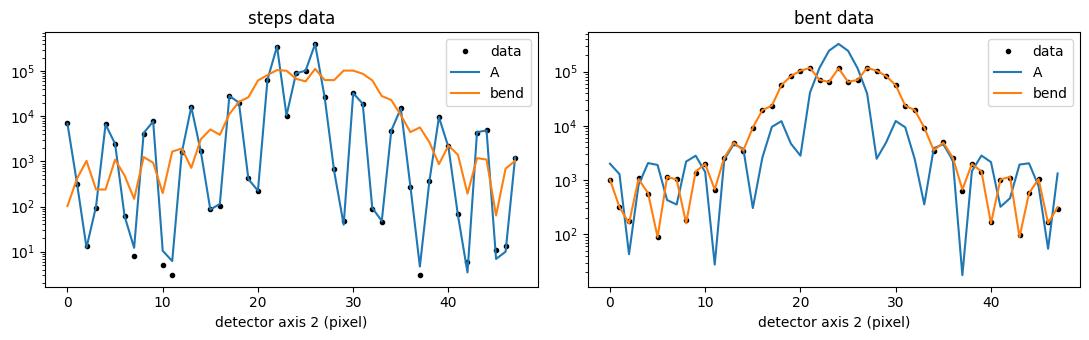

In [10]:
# profile along the rod through the Bragg peak: data and best models
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for axis, name in zip(axes, ("steps data", "bent data")):
    iobs = iobs_steps if name == "steps data" else iobs_bent
    centre = np.unravel_index(np.argmax(iobs), shape)
    axis.semilogy(iobs[centre[0], centre[1]], "k.", label="data")
    for model, geometry in (("A", slabs), ("bend", outline)):
        fitter = DomainModelFit(iobs, mask, geometry.astype(np.int32))
        intensity = fitter.model_intensity(results[name][model])
        axis.semilogy(intensity[centre[0], centre[1]], label=model)
    axis.set_title(name)
    axis.set_xlabel("detector axis 2 (pixel)")
    axis.legend()
fig.tight_layout()

## 4. On measured data

The same calls apply to a real scan, with arrays from the phasing:

```python
iobs = np.load("pynx_phasing/S1_pynx_input_data.npz")["data"]
mask = np.load("pynx_phasing/S1_pynx_input_mask.npz")["mask"]
mode = ...  # complex reconstruction mode, same phasing (before flip)

domains, seeds = segment_domains(np.abs(mode))
ramps = np.array([d["ramp"] for d in measure_domain_phases(mode, seeds)])
fitter = DomainModelFit(iobs, mask, seeds)
steps = fitter.fit("A", ramps=ramps)
```

For the bend model, use the outline of a reconstruction phased with a
support fixed to a less-deformed state of the same particle. Before
trusting a choice on real data, repeat sections 1-3 with the real mask
and photon count.